# Coding lab (45 minutes): From random variables to prediction

**Chapter 1 · Random Variables, Distributions, and Limits**  
**Format:** Run → observe → fill a short expression → change a parameter → explain.  
**Tools:** Python, NumPy, SciPy, and Matplotlib (already used in the lecture).

This is **not** a from-scratch programming exam. Most code is provided. Your job is to link the output to **probability, the LLN, the CLT, conditional expectation, and long-run prediction error**.

| Part | Topic | Time |
|---|---|---:|
| 1 | Conditional probabilities and distributions | 8 min |
| 2 | LLN for frequencies and prediction error | 10 min |
| 3 | CLT for a sample proportion | 12 min |
| 4 | Perfect fit, OLS, and long-run prediction | 15 min |
| **Total** | | **45 min** |

### A different data-generating process from the lecture

Suppose $X$ is a numerical score between $-2$ and $2$, and $Y$ indicates whether an event occurs ($Y=1$) or not ($Y=0$). We model

$$
X\sim\mathrm{Uniform}(-2,2),\qquad
Y\mid X=x\sim\mathrm{Bernoulli}(p(x)),\qquad
p(x)=\frac{1}{1+e^{-3x}}.
$$

For binary outcomes, $\mathbb E[Y\mid X=x]=\mathbb P(Y=1\mid X=x)=p(x)$: the **conditional expectation is a probability**. Unlike the lecture's $x^2$ example, this regression function is S-shaped.

**Working practice:** You may use AI or documentation to explain an unfamiliar line or suggest a parameter change, but **run the code, inspect the output, and write your own statistical interpretation**. Only a few expressions are left to complete. In Part 4, you will use one-covariate OLS, which you already know.

## Part 1 — Conditional probabilities and distributions (8 min)

**Before running the code:** Predict $\mathbb P(Y=1)$. Hint: the distribution of $X$ is symmetric around zero and $p(-x)=1-p(x)$.

1. Run the next cell and describe the shape of the conditional expectation.
2. **Fill gap A:** Calculate the observed frequency of $Y=1$.
3. Compare your result with the theoretical value $\mathbb P(Y=1)=\mathbb E[Y]=0.5$.
4. Explain why the scatter consists only of zeros and ones while the conditional expectation is a smooth curve.

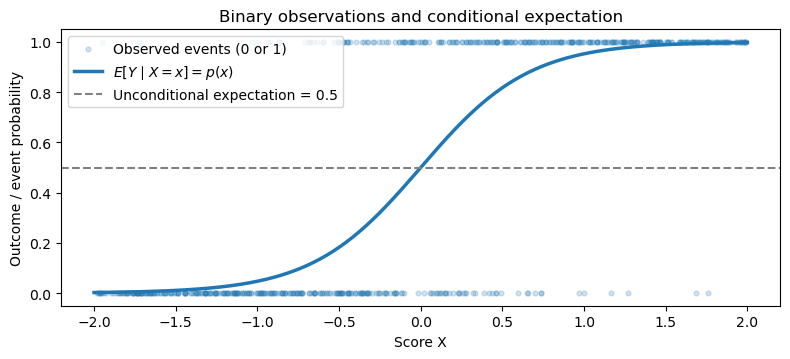

Empirical P(Y=1): 0.5030
Theoretical P(Y=1): 0.5000


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


def logistic(z):
    """Transform a real number into a probability between 0 and 1."""
    return 1 / (1 + np.exp(-z))


def simulate(n, seed):
    """Simulate n independent pairs (X, Y) and their true event probabilities."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(-2, 2, size=n)
    p = logistic(3 * x)
    y = rng.binomial(1, p)
    return x, y, p


N = 5_000                      # CHANGE: try 100, then 5_000
x_data, y_data, p_data = simulate(N, seed=501)

grid = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.scatter(x_data[:600], y_data[:600], s=12, alpha=0.20, label="Observed events (0 or 1)")
ax.plot(grid, logistic(3 * grid), lw=2.5, label=r"$E[Y\mid X=x]=p(x)$")
ax.axhline(0.5, ls="--", color="gray", label="Unconditional expectation = 0.5")
ax.set(xlabel="Score X", ylabel="Outcome / event probability", title="Binary observations and conditional expectation")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

# GAP A — replace None with one NumPy expression.
event_rate = np.mean(y_data == 1)   # e.g. np.mean( ... )

if event_rate is None:
    print("GAP A: calculate the relative frequency of Y = 1.")
else:
    print(f"Empirical P(Y=1): {event_rate:.4f}")
    print("Theoretical P(Y=1): 0.5000")

## Part 2 — LLN for frequencies and prediction errors (10 min)

For **a fixed prediction function** $g$, its population squared-error risk is

$$
R(g)=\mathbb E[(Y-g(X))^2],
$$

and its empirical counterpart is $\widehat R_n(g)=n^{-1}\sum_{i=1}^n(Y_i-g(X_i))^2$.

Because $m(x)=p(x)$ is the conditional expectation, it minimizes population squared-error risk. Moreover, since $Y\mid X$ is Bernoulli,

$$
R(m)=\mathbb E[\operatorname{Var}(Y\mid X)]
=\mathbb E[p(X)(1-p(X))].
$$

In this particular model, $R(m)=\tanh(3)/12\approx 0.083$ (you do **not** need to derive the integral).

1. Run the plot of the running event frequency.
2. **Fill gap B:** Calculate the running MSE of the fixed oracle predictor $m(x)=p(x)$.
3. Compare both curves with their population targets. What happens at small versus large $n$?
4. **Change** `N` in Part 1 from `5_000` to `100`, rerun Part 1 and 2, and compare the fluctuations. Set it back to `5_000` afterwards.

**Key distinction:** The LLN justifies evaluating a **fixed** prediction rule on i.i.d. observations. It does not by itself justify fitting an arbitrarily flexible function on those same observations and interpreting its training MSE as population risk.

In [ ]:
n_axis = np.arange(1, N + 1)
running_event_rate = np.cumsum(y_data == 1) / n_axis

# GAP B — use np.cumsum and n_axis to obtain the running squared error.
running_oracle_mse = None  # TODO: ...

oracle_risk = np.tanh(3) / 12
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].plot(n_axis, running_event_rate, lw=1.3, label="Empirical event frequency")
axes[0].axhline(0.5, ls="--", color="black", label="Population probability = 0.5")
axes[0].set(title="LLN: Event probability", ylabel="Relative frequency")
axes[0].legend(fontsize=8)

if running_oracle_mse is None:
    axes[1].text(0.5, 0.5, "Complete GAP B to see the curve", ha="center",
                 va="center", transform=axes[1].transAxes)
else:
    assert len(running_oracle_mse) == N, "Expected one running MSE per observation"
    axes[1].plot(n_axis, running_oracle_mse, lw=1.3, label="Empirical oracle MSE")
axes[1].axhline(oracle_risk, ls="--", color="black", label="Population oracle risk")
axes[1].set(title="LLN: Fixed prediction rule", ylabel="Squared prediction error")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlim(10, N)
    ax.set_xlabel("Sample size n")
fig.tight_layout()
plt.show()

## Part 3 — CLT for a sample proportion (12 min)

Marginally, $Y$ is Bernoulli with $\mathbb E[Y]=0.5$ and $\operatorname{Var}(Y)=0.25$. The CLT therefore says

$$
Z_n=\frac{\sqrt n(\overline Y_n-0.5)}{0.5}
\xrightarrow{d}N(0,1).
$$

The code below draws **4,000 independent samples**, each of size `n_clt`. This produces 4,000 values of the standardized sample mean.

1. **Fill gap C:** Standardize the simulated sample means using the formula above.
2. **Change** `n_clt` from `10` to `40`, then `200`, and rerun. Describe how the histograms change.
3. Compare the simulated fraction with $|Z_n|>2$ to the Normal approximation $2[1-\Phi(2)]\approx0.0455$.
4. Why does a Normal approximation emerge although each individual $Y_i$ is only 0 or 1?

In [ ]:
R = 4_000
n_clt = 10                   # CHANGE: 10 -> 40 -> 200

rng_clt = np.random.default_rng(502)
x_mc = rng_clt.uniform(-2, 2, size=(R, n_clt))
y_mc = rng_clt.binomial(1, logistic(3 * x_mc))
sample_means = np.mean(y_mc, axis=1)

# GAP C — use the CLT formula stated above.
z = None  # TODO: ...

fig, ax = plt.subplots(figsize=(8, 3.7))
if z is None:
    ax.text(0.5, 0.5, "Complete GAP C to see the histogram", ha="center",
            va="center", transform=ax.transAxes)
else:
    ax.hist(z, bins=np.linspace(-4, 4, 41), density=True, alpha=0.6,
            label="Monte Carlo standardized means")
    print(f"Simulated P(|Z| > 2) = {np.mean(np.abs(z)>2):.4f}")
    print(f"Approx.  P(|Z| > 2) = {2 * stats.norm.sf(2):.4f}")
    print(f"SD(sample mean), simulated = {np.std(sample_means, ddof=1):.4f}")
    print(f"SD(sample mean), theoretical = {0.5 / np.sqrt(n_clt):.4f}")

normal_grid = np.linspace(-4, 4, 400)
ax.plot(normal_grid, stats.norm.pdf(normal_grid), "k--", lw=2,
        label="Standard Normal density")
ax.set(xlabel="Standardized sample mean", ylabel="Density",
       title=f"CLT for binary observations (n = {n_clt})", xlim=(-4, 4))
ax.legend()
fig.tight_layout()
plt.show()

## Part 4 — Perfect fit, OLS, and long-run prediction (15 min)

We know that the conditional expectation minimizes the **population mean squared prediction error**

$$
R(g)=\mathbb E[(Y-g(X))^2].
$$

**The tempting shortcut:** Why not choose the function that makes the *observed* squared errors as small as possible? An unrestricted curve can pass through all initial observations and achieve empirical MSE $=0$. Does that mean it predicts new observations perfectly?

We compare three functions:

- **OLS predictor:** $\widehat g_{\mathrm{OLS}}(x)=\widehat a+\widehat b x$, fitted using the original data. You already know how to fit a straight line with one covariate; no other estimation method is required.
- **Conditional expectation (oracle):** $m(x)=p(x)=1/(1+e^{-3x})$. We know this function because *we specified the simulation model*.
- **Interpolating curve:** The provided code joins the initial observations. You do **not** need to understand or implement an interpolation algorithm; it serves only as the overfitting example from the lecture.

Once all three functions have been constructed, **keep them fixed**. Evaluate them in repeated experiments that draw fresh $(X,Y)$ pairs.

**Task 1 (5 min).** **Fill gap D:** Fit a one-covariate OLS line using `np.polyfit` (which returns *slope, intercept*). Run the code. Which function has the smallest MSE on the initial observations? Is the OLS line the conditional expectation?

**Task 2 (5 min).** Look at the right-hand graph. Why does the interpolator's zero initial-sample MSE not translate into zero prediction error on new observations? Which function has the smallest long-run squared error?

**Task 3 (3 min).** **Change** `n_initial` from `25` to `10`, then `70`, and rerun this part. How do the OLS coefficients and the interpolating curve change? Compare their long-run errors.

**Task 4 (2 min).** Explain why the LLN applies to the average squared errors across fresh repetitions **after** the prediction functions have been fixed. Does the LLN alone guarantee that minimizing the training MSE gives a good predictor?

**Important:** No inference about OLS coefficients and no cross-validation procedure is required. The goal is to connect the concepts already developed in the lecture: conditional expectation, squared prediction error, independent repetitions, and the LLN.

In [ ]:
# Step 1: Construct initial observations and a curve that interpolates them.
n_initial = 25                     # CHANGE: 25 -> 10 -> 70
x_initial, y_initial, _ = simulate(n_initial, seed=503)

order = np.argsort(x_initial)
x_sorted = x_initial[order]
y_sorted = y_initial[order]


def interpolator(x):
    """Provided demonstration curve (not a method you need to learn)."""
    return np.interp(np.asarray(x), x_sorted, y_sorted)


def oracle_predictor(x):
    """Known conditional expectation for this simulated population."""
    return logistic(3 * np.asarray(x))


# GAP D — Fit Y on an intercept and the single covariate X by OLS.
# Hint: np.polyfit(x, y, deg=1) returns (slope, intercept).
b_hat, a_hat = None, None  # TODO: replace with one line of code


def fitted_ols(x):
    return a_hat + b_hat * np.asarray(x)


ols_ready = (a_hat is not None) and (b_hat is not None)
if not ols_ready:
    print("GAP D: Fit the OLS line to include it in the comparison.")
else:
    print(f"OLS line: fitted y = {a_hat:.3f} + {b_hat:.3f} x")

# Keep all candidate functions fixed after this point.
predictors = {
    "Interpolator": interpolator,
    "Conditional expectation": oracle_predictor,
}
if ols_ready:
    predictors["Fitted OLS line"] = fitted_ols

print("\nMSE on the *original* observations:")
for name, g in predictors.items():
    train_mse = np.mean((y_initial - g(x_initial))**2)
    print(f"  {name:27s}: {train_mse:.5f}")

# Step 2: Draw independent NEW observations in each repetition.
R_long = 2_000                       # Number of independent repetitions
batch_size = 20                     # New (X,Y) pairs per repetition

x_future, y_future, _ = simulate(R_long * batch_size, seed=504)
x_future = x_future.reshape(R_long, batch_size)
y_future = y_future.reshape(R_long, batch_size)

repetitions = np.arange(1, R_long + 1)
running_errors = {}
for name, g in predictors.items():
    mse_each_repetition = np.mean((y_future - g(x_future))**2, axis=1)
    running_errors[name] = np.cumsum(mse_each_repetition) / repetitions

# Step 3: Compare the initial fit and errors on independent new observations.
plot_grid = np.linspace(-2, 2, 400)
colors = {
    "Interpolator": "tab:green",
    "Fitted OLS line": "tab:orange",
    "Conditional expectation": "tab:blue",
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(x_initial, y_initial, color="black", alpha=0.75,
                s=24, zorder=5, label="Original observations")
for name, g in predictors.items():
    axes[0].plot(plot_grid, g(plot_grid), lw=2,
                 color=colors[name], label=name)
axes[0].set(xlabel="X", ylabel="Y / predicted value",
            title="How well do we fit the original data?", xlim=(-2, 2))
axes[0].legend(fontsize=8)

for name, running_mse in running_errors.items():
    axes[1].plot(repetitions, running_mse, lw=1.6,
                 color=colors[name], label=name)
axes[1].axhline(oracle_risk, color="tab:blue", ls="--", alpha=0.7,
                label="Oracle population MSE")
axes[1].set_xscale("log")
axes[1].set_xlim(10, R_long)
axes[1].set(xlabel="Number of independent repetitions",
            ylabel="Average squared prediction error",
            title="How well do we predict new observations?")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print("\nAverage MSE across all new experiments:")
for name, running_mse in running_errors.items():
    print(f"  {name:27s}: {running_mse[-1]:.5f}")
print(f"  {'Oracle population MSE':27s}: {oracle_risk:.5f}")


### Exit ticket — brief answers

1. **LLN:** Which empirical quantities approach population expectations? Why do we hold the functions fixed when evaluating squared prediction errors on new observations?
2. **CLT:** What does the CLT tell us about empirical averages beyond the LLN?
3. **Conditional expectation:** Why is $m(x)=\mathbb E[Y\mid X=x]$ the best population predictor under squared error? Can a conditional expectation be affine?
4. **Fit versus prediction:** Why can a curve have zero squared error on its original observations but nonzero long-run prediction error? Why can an OLS fit still be worse than the conditional expectation on new data?

**If you finish early:** Change the coefficient `3` in both `simulate` and `oracle_predictor` to `1`. Re-run the notebook. Predict how the conditional expectation and the prediction errors will change. Keep the simulation model and oracle definition consistent.